In [4]:
import pandas as pd
import numpy as np

# Membaca dataset
df = pd.read_csv('/content/Survey-form for Risk Factors (Responses)-1.csv')

# Melihat ukuran dataset
print("Ukuran dataset:", df.shape)

# Melihat 5 data pertama
display(df.head())

# Memeriksa jumlah data kosong
print("Jumlah data kosong:", df.isnull().sum().sum())


Ukuran dataset: (100, 64)


,User_Id,Timestamp,Gender,Job Profile,Experience ( in years),Project Type (Type of project you are working),Organization size,Country,The problem is faced due to the risk factors in the software design phase.,Requirements Document (RD):- Software developers examine the requirements document to ensure that the requirements listed in the document are understandable. [(RD1) Requirement document is not clear for developers],...,"Specifying Design Activity (SD):- It is the activity that identifies components, defines data flow between them, and specifies the functionalities, data input, data output, and resource utilization for each component. [(SD8)Incorrect integration and changes in function]","Specifying Design Activity (SD):- It is the activity that identifies components, defines data flow between them, and specifies the functionalities, data input, data output, and resource utilization for each component. [(SD9)Wrong clustering and implementation of functions]","Documenting Design Activity (DD):- The main output of the design phase (i.e. design document DD) is prepared in this activity. It provides the solution's framework, which assists the software developer in maintaining and controlling the software design during the implementation. [(DD1) Incomplete design document]","Documenting Design Activity (DD):- The main output of the design phase (i.e. design document DD) is prepared in this activity. It provides the solution's framework, which assists the software developer in maintaining and controlling the software design during the implementation. [(DD2) Large design document]","Documenting Design Activity (DD):- The main output of the design phase (i.e. design document DD) is prepared in this activity. It provides the solution's framework, which assists the software developer in maintaining and controlling the software design during the implementation. [(DD3) Unclear design document]","Documenting Design Activity (DD):- The main output of the design phase (i.e. design document DD) is prepared in this activity. It provides the solution's framework, which assists the software developer in maintaining and controlling the software design during the implementation. [(DD4) Inconsistent design documenting]","Documenting Design Activity (DD):- The main output of the design phase (i.e. design document DD) is prepared in this activity. It provides the solution's framework, which assists the software developer in maintaining and controlling the software design during the implementation. [(DD5) Lack of quality software documents]","Documenting Design Activity (DD):- The main output of the design phase (i.e. design document DD) is prepared in this activity. It provides the solution's framework, which assists the software developer in maintaining and controlling the software design during the implementation. [(DD6) Absence of quality architectural and design document]","Documenting Design Activity (DD):- The main output of the design phase (i.e. design document DD) is prepared in this activity. It provides the solution's framework, which assists the software developer in maintaining and controlling the software design during the implementation. [(DD7) Changes of design document]","Documenting Design Activity (DD):- The main output of the design phase (i.e. design document DD) is prepared in this activity. It provides the solution's framework, which assists the software developer in maintaining and controlling the software design during the implementation. [(DD8) Ambiguity of design document]"
0,1,22-01-2022 02:57,Male,Software Developer/Programmer,5 years or less,Web based,Large (>1000),India,Yes,Neutral,...,Strongly Agree,Agree,Strongly Agree,Agree,Agree,Agree,Agree,Disagree,Strongly Agree,Strongly Agree
1,2,22-01-2022 08:50,Male,Team Leader,5 to 15 year,Database Project,Large (>1000),India,Yes,Neutral,...,Neutral,Agree,Neutral,Neutral,Strongly Agree,Neutral,Neutral,Neutral,Neutral,Neutral
2,3,22-01-2022 10:01,Female,Other,5 to 15 year,O

Jumlah data kosong: 0


In [5]:

# Mengambil 55 kolom pertanyaan kuesioner
data_pertanyaan = df.iloc[:, 9:64].copy()

# Mengubah jawaban menjadi angka
skor = {
    'Strongly Disagree': 1,
    'Disagree': 2,
    'Neutral': 3,
    'Agree': 4,
    'Strongly Agree': 5
}

data_numerik = data_pertanyaan.replace(skor)

# Menghitung rata-rata 55 pertanyaan
nilai_responden = data_numerik.mean(axis=1)

# Membuat tabel hasil
hasil = pd.DataFrame({
    'Responden': range(1, 101),
    'Nilai_Rata_Rata': nilai_responden
})

display(hasil)

print("Jumlah sampel:", len(hasil))
print("Rata-rata keseluruhan:", nilai_responden.mean())


/tmp/ipykernel_553/3525731234.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_numerik = data_pertanyaan.replace(skor)


,Responden,Nilai_Rata_Rata
0,1,3.854545
1,2,3.090909
2,3,4.054545
3,4,4.018182
4,5,4.036364
...,...,...
95,96,3.945455
96,97,2.872727
97,98,4.018182
98,99,4.836364


Jumlah sampel: 100
Rata-rata keseluruhan: 3.6885454545454546


In [6]:
# Menghitung estimasi titik dan interval Z

n = len(nilai_responden)

# Rata-rata sampel
mean = nilai_responden.mean()

# Standar deviasi sampel
std = nilai_responden.std(ddof=1)

# Nilai Z untuk tingkat kepercayaan 95%
z = 1.96

# Standard Error
se = std / np.sqrt(n)

# Menghitung batas interval
batas_bawah = mean - (z * se)
batas_atas = mean + (z * se)

print("ESTIMASI TITIK DAN INTERVAL Z")
print("--------------------------------")
print("Jumlah sampel:", n)
print("Rata-rata sampel:", mean)
print("Standar deviasi:", std)
print("Standard Error:", se)
print("Nilai Z:", z)
print("Tingkat kesalahan: 5%")
print("Estimasi titik:", mean)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)
print("Interval kepercayaan: [", batas_bawah, ",", batas_atas, "]")


ESTIMASI TITIK DAN INTERVAL Z
--------------------------------
Jumlah sampel: 100
Rata-rata sampel: 3.6885454545454546
Standar deviasi: 0.4721381863224881
Standard Error: 0.047213818632248813
Nilai Z: 1.96
Tingkat kesalahan: 5%
Estimasi titik: 3.6885454545454546
Batas bawah: 3.596006370026247
Batas atas: 3.781084539064662
Interval kepercayaan: [ 3.596006370026247 , 3.781084539064662 ]


In [7]:
# METODE JACKKNIFE

jackknife_means = []

for i in range(n):

    # Menghapus satu data secara bergantian
    sampel_jackknife = nilai_responden.drop(
        nilai_responden.index[i]
    )

    # Menghitung rata-rata
    rata_rata = sampel_jackknife.mean()

    jackknife_means.append(rata_rata)

# Menghitung rata-rata hasil Jackknife
rata_jackknife = np.mean(jackknife_means)

# Menghitung standar error Jackknife
jackknife_se = np.sqrt(
    (n-1)/n * np.sum(
        (np.array(jackknife_means) - rata_jackknife)**2
    )
)

print("HASIL JACKKNIFE")
print("--------------------------")
print("Jumlah resampling:", len(jackknife_means))
print("Rata-rata Jackknife:", rata_jackknife)
print("Standar Error Jackknife:", jackknife_se)


HASIL JACKKNIFE
--------------------------
Jumlah resampling: 100
Rata-rata Jackknife: 3.6885454545454546
Standar Error Jackknife: 0.047213818632248904


In [8]:
# METODE BOOTSTRAPPING

np.random.seed(42)

bootstrap_means = []

for i in range(1000):

    # Mengambil sampel secara acak dengan pengembalian
    sampel_bootstrap = np.random.choice(
        nilai_responden,
        size=n,
        replace=True
    )

    # Menghitung rata-rata sampel
    rata_rata = np.mean(sampel_bootstrap)

    bootstrap_means.append(rata_rata)

# Menghitung rata-rata hasil Bootstrap
rata_bootstrap = np.mean(bootstrap_means)

# Menghitung standar deviasi hasil Bootstrap
std_bootstrap = np.std(bootstrap_means, ddof=1)

print("HASIL BOOTSTRAPPING")
print("--------------------------")
print("Jumlah iterasi:", len(bootstrap_means))
print("Rata-rata Bootstrap:", rata_bootstrap)
print("Standar Deviasi Bootstrap:", std_bootstrap)


HASIL BOOTSTRAPPING
--------------------------
Jumlah iterasi: 1000
Rata-rata Bootstrap: 3.686095636363636
Standar Deviasi Bootstrap: 0.04600421614097692


In [9]:
# TABEL PERBANDINGAN HASIL

perbandingan = pd.DataFrame({
    'Metode': [
        'Estimasi Titik',
        'Jackknife',
        'Bootstrapping'
    ],
    'Rata-rata': [
        mean,
        rata_jackknife,
        rata_bootstrap
    ]
})

display(perbandingan)


,Metode,Rata-rata
0,Estimasi Titik,3.688545
1,Jackknife,3.688545
2,Bootstrapping,3.686096


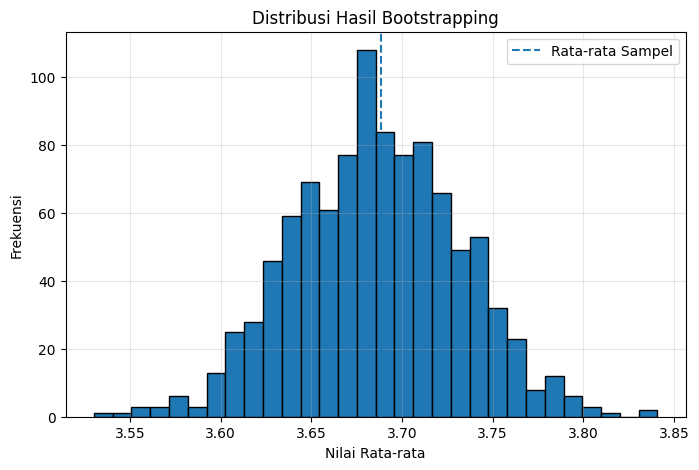

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    bootstrap_means,
    bins=30,
    edgecolor='black'
)

plt.axvline(
    mean,
    linestyle='--',
    label='Rata-rata Sampel'
)

plt.title('Distribusi Hasil Bootstrapping')
plt.xlabel('Nilai Rata-rata')
plt.ylabel('Frekuensi')
plt.legend()
plt.grid(alpha=0.3)

plt.show()
